[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MuhammadErlanggaKurniawan/ets-ml2-kelompok/blob/main/notebooks/eksperimen_rijal_rl.ipynb)

# Eksperimen Reinforcement Learning: Seberapa Peka Agen terhadap Reward?
**Dikerjakan oleh:** Rijal Apuila Khufi · lanjutan dari notebook utama `ETS_ML2_Kesegaran_Ayam.ipynb`

Notebook ini menguji **agen reinforcement learning** lebih jauh. Data dan fiturnya sama persis dengan notebook utama.


---
## Langkah 0 — Persiapan dan Pengolahan Data
Pada tahap ini, dataset diunduh dan diolah dengan membentuk label, meringkas data setiap 5 menit, serta menghasilkan 19 fitur untuk proses klasifikasi dan Reinforcement Learning.

In [17]:
import hashlib
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import LeaveOneGroupOut

SEED = 42
CLASSES = ["Fresh", "Semi-fresh", "Spoiled"]

URL = (
    "https://raw.githubusercontent.com/"
    "talhaanwarch/chicken_assessment_e-nose/"
    "e7e3ca686bce0ef3e5c59f9833c85a3190c36e6e/"
    "complete_data.csv"
)

SHA256 = "7c9920fcfe523af1ee2855d53f13334ddba93db5135d7868b9f63c5cd488d953"

path = Path("data/raw/complete_data.csv")
path.parent.mkdir(parents=True, exist_ok=True)

if not path.exists():
    urllib.request.urlretrieve(URL, path)

assert hashlib.sha256(path.read_bytes()).hexdigest() == SHA256, (
    "Dataset tidak sesuai dengan sumber asli."
)

SENSOR_NAMES = {
    "s1": "MQ-135",
    "s2": "MQ-2",
    "s3": "MQ-3",
    "s4": "MQ-6",
    "s5": "MQ-7",
    "s6": "MQ-9",
    "s8": "Kelembapan"
}

raw = pd.read_csv(path).rename(
    columns={**SENSOR_NAMES, "hour": "jam", "group": "sesi"}
)

MQ = ["MQ-135", "MQ-2", "MQ-3", "MQ-6", "MQ-7", "MQ-9"]
SENSORS = MQ + ["Kelembapan"]

long_session = raw.groupby("sesi")["jam"].transform("max") > 15

raw["label"] = np.select(
    [
        raw["jam"] <= np.where(long_session, 8, 5),
        raw["jam"] <= np.where(long_session, 16, 10)
    ],
    [0, 1],
    default=2
)


def make_windows(readings):
    r = readings.copy()

    r["urutan"] = r.groupby(["sesi", "jam"]).cumcount()
    r["n"] = r.groupby(["sesi", "jam"])["jam"].transform("size")
    r["jendela"] = r["urutan"] * 12 // r["n"]

    agregasi = {
        col: (col, "mean")
        for col in SENSORS
    }
    agregasi["label"] = ("label", "first")

    return (
        r.groupby(["sesi", "jam", "jendela"])
        .agg(**agregasi)
        .reset_index()
    )


def make_features(win):
    level = np.log1p(win[MQ].clip(lower=0))

    reference = (
        level.where(win["jam"] == 1)
        .groupby(win["sesi"])
        .transform("mean")
    )

    keep = (win["jam"] >= 2).to_numpy()

    rows = win[keep].reset_index(drop=True)
    level = level[keep].reset_index(drop=True)
    reference = reference[keep].reset_index(drop=True)

    gas = rows[MQ].clip(lower=0)

    features = pd.concat(
        [
            level.add_prefix("level_"),
            gas.div(
                gas.sum(axis=1) + 1,
                axis=0
            ).add_prefix("porsi_"),
            (level - reference).add_prefix("naik_"),
            rows[["Kelembapan"]]
        ],
        axis=1
    )

    return features, rows


features, data = make_features(make_windows(raw))

X = features.to_numpy()
y = data["label"].to_numpy()
groups = data["sesi"].to_numpy()


def loso(make_model, X_=None):
    X_ = X if X_ is None else X_

    pred = np.empty_like(y)
    proba = np.zeros((len(y), len(CLASSES)))

    cv = LeaveOneGroupOut()

    for train_idx, test_idx in cv.split(X_, y, groups):
        model = make_model()
        model.fit(X_[train_idx], y[train_idx])

        pred[test_idx] = model.predict(X_[test_idx])

        fold_proba = model.predict_proba(X_[test_idx])
        proba[np.ix_(
            test_idx,
            model.classes_.astype(int)
        )] = fold_proba

    return pred, proba


def score(pred):
    return {
        "akurasi": round(accuracy_score(y, pred), 3),
        "macro_f1": round(
            f1_score(y, pred, average="macro"), 3
        )
    }


def make_rf():
    return RandomForestClassifier(
        n_estimators=300,
        max_depth=6,
        random_state=SEED,
        n_jobs=-1
    )


print(
    f"Data siap: {len(data)} jendela, "
    f"{X.shape[1]} fitur, "
    f"{len(np.unique(groups))} sesi."
)

Data siap: 3468 jendela, 19 fitur, 15 sesi.


---
## Langkah 1 — Prediksi Random Forest dan Pengambilan Keputusan Agen
Pada tahap ini, hasil prediksi Random Forest digunakan oleh agen Reinforcement Learning untuk menentukan tindakan Jual, Cek Manual, atau Buang berdasarkan kondisi kesegaran daging ayam.

In [19]:
_, proba_rf = loso(make_rf)

predicted = proba_rf.argmax(axis=1)
layak = y <= 1

ACTIONS = ["Jual", "Cek manual", "Buang"]

STATE_NAMES = [
    f"{kelas} ({'ragu' if ragu else 'yakin'})"
    for kelas in CLASSES
    for ragu in (False, True)
]

RL_TEST_SESSIONS = [
    [0, 10, 11],
    [2, 8, 13],
    [1, 6, 9],
    [4, 7, 14],
    [3, 5, 12]
]

FOLDS = [
    (
        np.flatnonzero(~np.isin(groups, sesi)),
        np.flatnonzero(np.isin(groups, sesi))
    )
    for sesi in RL_TEST_SESSIONS
]


def jalankan_agen(
    jual_layak=1.0,
    jual_busuk=-5.0,
    cek=0.5,
    buang_layak=-1.0,
    buang_busuk=1.0,
    ambang_yakin=0.7,
    epsilon=0.1,
    iterasi=3000,
    seeds=5
):
    state = predicted * 2 + (
        proba_rf.max(axis=1) < ambang_yakin
    )

    reward = np.column_stack([
        np.where(layak, jual_layak, jual_busuk),
        np.full(len(y), cek),
        np.where(layak, buang_layak, buang_busuk)
    ])

    curves = []
    policies = []

    for train_idx, test_idx in FOLDS:
        for seed in range(seeds):
            rng = np.random.default_rng(seed)

            Q = np.zeros((6, 3))
            N = np.zeros((6, 3))
            curve = []

            for t in range(1, iterasi + 1):
                i = rng.choice(train_idx)
                s = state[i]

                if rng.random() < epsilon:
                    a = rng.integers(3)
                else:
                    a = int(np.argmax(Q[s]))

                N[s, a] += 1
                Q[s, a] += (reward[i, a] - Q[s, a]) / N[s, a]

                if t == 1 or t % 100 == 0:
                    test_actions = Q.argmax(axis=1)[state[test_idx]]
                    test_reward = reward[test_idx, test_actions].mean()
                    curve.append(test_reward)

            curves.append(curve)
            policies.append(Q.argmax(axis=1))

    policy = [
        int(
            np.bincount(
                [p[s] for p in policies],
                minlength=3
            ).argmax()
        )
        for s in range(6)
    ]

    action = np.array(policy)[state]

    return {
        "reward_akhir": round(
            float(np.mean(curves, axis=0)[-1]), 3
        ),
        "aturan": dict(zip(
            STATE_NAMES,
            [ACTIONS[a] for a in policy]
        )),
        "busuk_terjual": int(
            ((action == 0) & ~layak).sum()
        ),
        "layak_terbuang": int(
            ((action == 2) & layak).sum()
        ),
        "persen_cek": round(
            100 * float((action == 1).mean()), 1
        ),
        "kurva": np.mean(curves, axis=0)
    }


def tabel_aturan(hasil_per_setting):
    return pd.DataFrame({
        nama: hasil["aturan"]
        for nama, hasil in hasil_per_setting.items()
    })


def tabel_dampak(hasil_per_setting):
    kolom = [
        "reward_akhir",
        "busuk_terjual",
        "layak_terbuang",
        "persen_cek"
    ]

    return pd.DataFrame({
        nama: {
            k: hasil[k] for k in kolom
        }
        for nama, hasil in hasil_per_setting.items()
    }).T


print("Siap Semua.")

Siap Semua.


---
## Evaluasi Awal Agen Reinforcement Learning
Pada tahap ini, dilakukan pengujian awal agen menggunakan parameter reward standar untuk mengevaluasi keputusan, reward akhir, dan jumlah pemeriksaan manual.

In [20]:
asli = jalankan_agen()

print(
    f"Reward akhir    : {asli['reward_akhir']}\n"
    f"Busuk terjual   : {asli['busuk_terjual']}\n"
    f"Cek manual      : {asli['persen_cek']}%"
)

display(
    pd.Series(
        asli["aturan"],
        name="Aksi"
    ).to_frame()
)

Reward akhir    : 0.605
Busuk terjual   : 0
Cek manual      : 47.2%


,Aksi
Fresh (yakin),Jual
Fresh (ragu),Jual
Semi-fresh (yakin),Cek manual
Semi-fresh (ragu),Cek manual
Spoiled (yakin),Buang
Spoiled (ragu),Cek manual


Agen memilih menjual ayam kategori Fresh, memeriksa secara manual kategori Semi-fresh, serta membuang ayam kategori Spoiled ketika prediksinya yakin. Jika prediksi Spoiled masih ragu, agen memilih pemeriksaan manual.

Hasil ini menunjukkan bahwa agen berhasil menerapkan kebijakan yang mengutamakan keamanan dalam simulasi. Namun, jumlah pemeriksaan manual masih cukup tinggi sehingga terdapat trade-off antara keamanan dan efisiensi.

---
## Langkah 3 — Analisis Pengaruh Denda Penjualan Ayam Busuk
Pada tahap ini, dilakukan pengujian variasi denda −2, −5, dan −10 untuk menganalisis pengaruh besarnya penalti terhadap keputusan dan kinerja agen Reinforcement Learning.

In [21]:
DENDA = [-2, -5, -10]

hasil_denda = {
    f"Jual busuk {denda}": jalankan_agen(
        jual_busuk=denda
    )
    for denda in DENDA
}

display(tabel_aturan(hasil_denda))
display(tabel_dampak(hasil_denda))

,Jual busuk -2,Jual busuk -5,Jual busuk -10
Fresh (yakin),Jual,Jual,Jual
Fresh (ragu),Jual,Jual,Jual
Semi-fresh (yakin),Jual,Cek manual,Cek manual
Semi-fresh (ragu),Cek manual,Cek manual,Cek manual
Spoiled (yakin),Buang,Buang,Buang
Spoiled (ragu),Cek manual,Cek manual,Cek manual


,reward_akhir,busuk_terjual,layak_terbuang,persen_cek
Jual busuk -2,0.676,71.0,104.0,28.3
Jual busuk -5,0.605,0.0,104.0,47.2
Jual busuk -10,0.509,0.0,104.0,47.2


Berdasarkan hasil eksperimen, perubahan denda menjual ayam busuk memengaruhi keputusan agen Reinforcement Learning.

Pada denda -2, agen memperoleh reward akhir sebesar 0,676 dengan 71 ayam busuk terjual dan 28,3% pemeriksaan manual. Ketika denda ditingkatkan menjadi -5, jumlah ayam busuk terjual turun menjadi 0, tetapi pemeriksaan manual meningkat menjadi 47,2%.

Pada denda -10, jumlah ayam busuk terjual tetap 0 dengan persentase pemeriksaan manual yang sama, yaitu 47,2%. Perubahan utama terlihat pada kondisi Semi-fresh (yakin), di mana agen memilih Jual pada denda -2, tetapi berubah menjadi Cek manual pada denda -5 dan -10.

Dapat disimpulkan bahwa denda -5 merupakan pilihan yang lebih seimbang dalam simulasi ini karena mampu mencegah penjualan ayam busuk tanpa memerlukan penalti yang lebih besar. Peningkatan denda menjadi -10 belum memberikan perubahan kebijakan yang lebih baik. Perbedaan reward akhir perlu ditafsirkan dengan hati-hati karena fungsi penalti yang digunakan juga berubah.

---
## Langkah 4 — Analisis Pengaruh Biaya Pemeriksaan Manual
Pada tahap ini, dilakukan pengujian variasi reward pemeriksaan manual sebesar 0,2, 0,5, dan 0,8 untuk menganalisis pengaruhnya terhadap keputusan dan kinerja agen Reinforcement Learning.

In [11]:
NILAI_CEK = [0.2, 0.5, 0.8]

hasil_cek = {
    f"cek {c}": jalankan_agen(cek=c)
    for c in NILAI_CEK
}

display(tabel_aturan(hasil_cek))
display(tabel_dampak(hasil_cek))

,cek 0.2,cek 0.5,cek 0.8
Fresh (yakin),Jual,Jual,Jual
Fresh (ragu),Jual,Jual,Jual
Semi-fresh (yakin),Cek manual,Cek manual,Cek manual
Semi-fresh (ragu),Cek manual,Cek manual,Cek manual
Spoiled (yakin),Buang,Buang,Cek manual
Spoiled (ragu),Cek manual,Cek manual,Cek manual


,reward_akhir,busuk_terjual,layak_terbuang,persen_cek
cek 0.2,0.497,0.0,104.0,47.2
cek 0.5,0.605,0.0,104.0,47.2
cek 0.8,0.784,0.0,0.0,71.2


Berdasarkan hasil eksperimen, perubahan reward pemeriksaan manual memengaruhi kebijakan agen Reinforcement Learning.

Pada nilai cek 0,2 dan 0,5, agen melakukan pemeriksaan manual sebesar 47,2%, dengan 0 ayam busuk terjual dan 104 sampel layak terbuang.

Ketika reward cek ditingkatkan menjadi 0,8, persentase pemeriksaan manual meningkat menjadi 71,2%, sedangkan jumlah sampel layak terbuang menurun menjadi 0. Hal ini terjadi karena agen memilih memeriksa kategori Spoiled (yakin) daripada langsung membuangnya.

Dapat disimpulkan bahwa semakin menguntungkan tindakan cek manual, agen cenderung melakukan lebih banyak pemeriksaan. Sebaliknya, ketika reward cek lebih rendah, agen cenderung membatasi pemeriksaan. Namun, pada pengujian ini, nilai 0,2 dan 0,5 menghasilkan keputusan yang sama.

Trade-off yang terjadi adalah meningkatnya kebutuhan pemeriksaan manual untuk mengurangi risiko membuang sampel yang sebenarnya masih layak. Seluruh hasil ini berlaku pada simulasi yang dilakukan.

---
## Langkah 5 — Analisis Pengaruh Ambang Keyakinan Model
Pada tahap ini, dilakukan pengujian variasi ambang keyakinan sebesar 0,6, 0,7, dan 0,8 untuk menganalisis pengaruhnya terhadap keputusan dan kinerja agen Reinforcement Learning.

In [22]:
AMBANG = [0.6, 0.7, 0.8]

hasil_ambang = {
    f"Ambang {ambang}": jalankan_agen(
        ambang_yakin=ambang
    )
    for ambang in AMBANG
}

display(tabel_aturan(hasil_ambang))
display(tabel_dampak(hasil_ambang))

,Ambang 0.6,Ambang 0.7,Ambang 0.8
Fresh (yakin),Jual,Jual,Jual
Fresh (ragu),Jual,Jual,Jual
Semi-fresh (yakin),Cek manual,Cek manual,Cek manual
Semi-fresh (ragu),Cek manual,Cek manual,Cek manual
Spoiled (yakin),Buang,Buang,Buang
Spoiled (ragu),Cek manual,Cek manual,Cek manual


,reward_akhir,busuk_terjual,layak_terbuang,persen_cek
Ambang 0.6,0.598,0.0,146.0,44.3
Ambang 0.7,0.605,0.0,104.0,47.2
Ambang 0.8,0.623,0.0,44.0,52.1


Berdasarkan hasil eksperimen, perubahan ambang keyakinan memengaruhi hasil keputusan agen Reinforcement Learning.

Pada ambang 0,6, diperoleh reward akhir 0,598, sebanyak 146 sampel layak terbuang, dan 44,3% pemeriksaan manual. Pada ambang 0,7, reward meningkat menjadi 0,605 dengan 104 sampel layak terbuang dan 47,2% pemeriksaan manual.

Ketika ambang dinaikkan menjadi 0,8, reward meningkat menjadi 0,623, jumlah sampel layak terbuang menurun menjadi 44, sedangkan pemeriksaan manual meningkat menjadi 52,1%.

Meskipun aturan tindakan agen tetap sama, perubahan ambang memengaruhi jumlah sampel yang dianggap yakin atau ragu. Ketiga pengujian menghasilkan 0 sampel busuk terjual.

Dapat disimpulkan bahwa ambang 0,8 memberikan hasil terbaik dari ketiga konfigurasi berdasarkan reward dan jumlah sampel layak yang tidak terbuang. Namun, konsekuensinya adalah meningkatnya pemeriksaan manual. Hasil ini hanya berlaku pada data simulasi yang diuji dan belum menjamin keamanan pada kondisi nyata.

---
## Langkah 6 — Analisis Pengaruh Epsilon terhadap Pembelajaran Agen
Pada tahap ini, dilakukan pengujian variasi epsilon sebesar 0,01, 0,1, dan 0,3 untuk menganalisis pengaruh tingkat eksplorasi terhadap proses pembelajaran dan reward agen Reinforcement Learning.

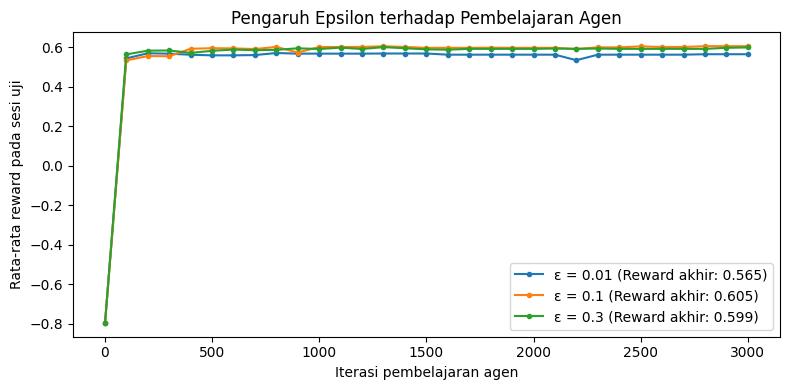

In [23]:
EPSILON = [0.01, 0.1, 0.3]

fig, ax = plt.subplots(figsize=(8, 4))

langkah = np.r_[1, np.arange(100, 3001, 100)]

for epsilon in EPSILON:
    hasil = jalankan_agen(epsilon=epsilon)

    ax.plot(
        langkah,
        hasil["kurva"],
        marker="o",
        markersize=3,
        label=f"ε = {epsilon} (Reward akhir: {hasil['reward_akhir']})"
    )

ax.set(
    xlabel="Iterasi pembelajaran agen",
    ylabel="Rata-rata reward pada sesi uji",
    title="Pengaruh Epsilon terhadap Pembelajaran Agen"
)

ax.legend()
plt.tight_layout()
plt.show()

Berdasarkan eksperimen perubahan nilai epsilon, diperoleh reward akhir sebesar 0,565 pada ε = 0,01, sebesar 0,605 pada ε = 0,10, dan sebesar 0,599 pada ε = 0,30.

Ketiga konfigurasi menunjukkan peningkatan reward yang cepat pada awal iterasi, kemudian cenderung stabil hingga 3.000 iterasi. Perbedaan kecepatan pembelajaran tidak terlalu jelas karena ketiga kurva memiliki pola yang hampir sama.

Dari segi hasil akhir, epsilon 0,10 memberikan reward tertinggi sebesar 0,605. Nilai tersebut menunjukkan bahwa eksplorasi sebesar 10% menghasilkan kinerja terbaik dalam pengujian ini.

Dapat disimpulkan bahwa eksplorasi yang terlalu rendah belum tentu menghasilkan kebijakan terbaik, sedangkan eksplorasi yang lebih tinggi juga tidak selalu meningkatkan reward. Namun, hasil ini perlu diuji kembali dengan beberapa random seed untuk memastikan konsistensinya.

---
## Langkah 7 — Kesimpulan


### Kesimpulan Eksperimen Reinforcement Learning

Berdasarkan seluruh eksperimen yang telah dilakukan, agen Reinforcement Learning mampu mempelajari kebijakan pengambilan keputusan untuk menentukan apakah daging ayam perlu dijual, diperiksa secara manual, atau dibuang.

Pada eksperimen awal, agen memperoleh reward sebesar 0,605 dengan 0 sampel busuk terjual dan 47,2% pemeriksaan manual.

Hasil pengujian menunjukkan bahwa perubahan denda menjual ayam busuk memengaruhi keputusan agen. Denda -5 menghasilkan kebijakan yang lebih aman dibandingkan -2 karena tidak terdapat ayam busuk yang dijual dalam simulasi.

Perubahan reward pemeriksaan manual juga memengaruhi kebijakan agen. Pada reward cek 0,8, pemeriksaan manual meningkat menjadi 71,2%, tetapi jumlah sampel layak terbuang menurun menjadi 0.

Pada eksperimen ambang keyakinan, nilai 0,8 menghasilkan reward tertinggi sebesar 0,623 dengan 44 sampel layak terbuang dan 52,1% pemeriksaan manual.

Sementara itu, eksperimen epsilon menunjukkan bahwa ε = 0,10 memberikan reward akhir tertinggi sebesar 0,605 dibandingkan ε = 0,01 dan ε = 0,30.

Secara keseluruhan, eksperimen menunjukkan adanya trade-off antara keamanan penjualan, biaya pemeriksaan manual, dan jumlah produk layak yang terbuang. Parameter agen perlu dipilih berdasarkan prioritas sistem, bukan hanya reward tertinggi. Hasil penelitian masih terbatas pada simulasi menggunakan dataset yang tersedia, sehingga diperlukan pengujian lebih lanjut sebelum diterapkan pada kondisi nyata.